In [ ]:
# Step 1: Install the required AI tools
!pip install -q transformers datasets evaluate accelerate gradio

import os,glob, zipfile
import pandas as pd
import numpy as np
import evaluate
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

# Step 2: Unzip "AI project.zip"
with zipfile.ZipFile("AI Project.zip", "r") as zip_ref:
    zip_ref.extractall("data")

# Automatically find the exact subfolder containing train.tsv
train_paths = glob.glob("data/**/train.tsv", recursive=True)
folder = os.path.dirname(train_paths[0])
print("Dataset found in:", folder)
# Step 3: Load the TSV files and labels.txt
# Note: In MasakhaNEWS TSV files, column 0 is category, column 1 is headline, column 2 is text
train_df = pd.read_csv(f"{folder}/train.tsv", sep="\t")
dev_df   = pd.read_csv(f"{folder}/dev.tsv", sep="\t")
test_df  = pd.read_csv(f"{folder}/test.tsv", sep="\t")

# Read the list of categories from labels.txt
with open(f"{folder}/labels.txt", "r") as f:
    label_names = [line.strip() for line in f if line.strip()]

# Create a dictionary to turn words into numbers (e.g., 'sports' -> 0)
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for i, name in enumerate(label_names)}
print("Categories found:", id2label)

# Step 4: Clean and prepare the data
def clean_data(df):
    # Rename columns clearly just in case headers differ
    # Combine headline and article text into one column
    df["full_text"] = df["headline"].fillna("") + ". " + df["text"].fillna("")
    # Convert text category into numbers (0, 1, 2...)
    df["label"] = df["category"].map(label2id)
    # Remove any empty rows
    df = df.dropna(subset=["label", "full_text"])
    df["label"] = df["label"].astype(int)
    return df[["full_text", "label"]]

train_clean = clean_data(train_df)
dev_clean   = clean_data(dev_df)
test_clean  = clean_data(test_df)

# Save clean CSV files (Required Deliverable!)
train_clean.to_csv("swahili_train.csv", index=False)
dev_clean.to_csv("swahili_dev.csv", index=False)
test_clean.to_csv("swahili_test.csv", index=False)

# Put data into Hugging Face format
dataset = DatasetDict({
    "train": Dataset.from_pandas(train_clean, preserve_index=False),
    "validation": Dataset.from_pandas(dev_clean, preserve_index=False),
    "test": Dataset.from_pandas(test_clean, preserve_index=False)
})

# Step 5: Load the Pre-trained African Language Model (AfroXLMR)
model_name = "Davlan/afro-xlmr-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Convert Swahili sentences into numbers (tokens) the AI understands
def tokenize_text(batch):
    return tokenizer(batch["full_text"], truncation=True, padding="max_length", max_length=128)

tokenized_data = dataset.map(tokenize_text, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

# Step 6: Set up Evaluation Metrics (Accuracy & F1 Score)
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def check_performance(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    acc = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    f1 = f1_metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    return {"accuracy": acc, "f1_score": f1}

# Step 7: Fine-Tune (Train) the Model
training_settings = TrainingArguments(
    output_dir="./my_swahili_model",
    eval_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    num_train_epochs=3,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_settings,
    train_dataset=tokenized_data["train"],
    eval_dataset=tokenized_data["validation"],
    compute_metrics=check_performance
)

print("Starting training...")
trainer.train()

# Step 8: Test the Model and Save It
results = trainer.evaluate(tokenized_data["test"])
print("Final Test Score:", results)

trainer.save_model("./final_swahili_ai")
tokenizer.save_pretrained("./final_swahili_ai")


Dataset found in: data/AI Project
Categories found: {0: 'business', 1: 'entertainment', 2: 'health', 3: 'politics', 4: 'religion', 5: 'sports', 6: 'technology'}


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

... (11 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,F1 Score
No log,0.423735,3,0.890756,0.870638


Final Test Score: {'eval_loss': 0.4237349331378937, 'eval_accuracy': 0.8907563025210085, 'eval_f1_score': 0.8706383690340646}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./final_swahili_ai/tokenizer_config.json',
 './final_swahili_ai/tokenizer.json')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import torch
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

#1 load saved model and tokenizer
tokenizer = AutoTokenizer.from_pretrained('./final_swahili_ai')
model = AutoModelForSequenceClassification.from_pretrained('./final_swahili_ai')
model.eval()
#2Predict category probabilities
def predict_news(text):
  inputs= tokenizer(text,return_tensors='pt',truncation=True, max_length=128)
  with torch.no_grad():
    logits = model(**inputs).logits
  probs = torch.softmax(logits, dim=1).squeeze().tolist()
  return{model.config.id2label.get(i,str(i)).capitalize(): round(score,4) for i, score in enumerate(probs)}
#quick self-test printed in colab
print('self-test result:', predict_news('Benki Kuu imetangaza viwango vipya vya riba mwaka huu.'))
#launch web interface
demo = gr.Interface(
    fn=predict_news,
    inputs=gr.Textbox(lines=3, label="Enter Swahili News", placeholder = 'Andika au bandika habari ya kiswahili hapa...', autofocus=True),
    outputs=gr.Label(num_top_classes=3, label="Predicted Category"),
    title="Swahili News AI Classifier", description=('Paste short swahili articles below to automatically classify its category.'),
    article=('tip:longer, complete sentences usually produce higher confidence scores'),examples=[['Benki kuu imetangaza viwango vipya vya riba mwaka huu.'],['timu ya taifa imeanza mazoezi makali kujiandaa na mechi ya kufuzu.']],
    theme = gr.themes.Soft(),
    submit_btn ='Classify News',
    clear_btn = 'Clear',
)

demo.launch(share=True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

self-test result: {'Business': 0.874, 'Entertainment': 0.0104, 'Health': 0.0223, 'Politics': 0.0393, 'Religion': 0.0116, 'Sports': 0.0173, 'Technology': 0.025}


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c1058c9029014663bb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


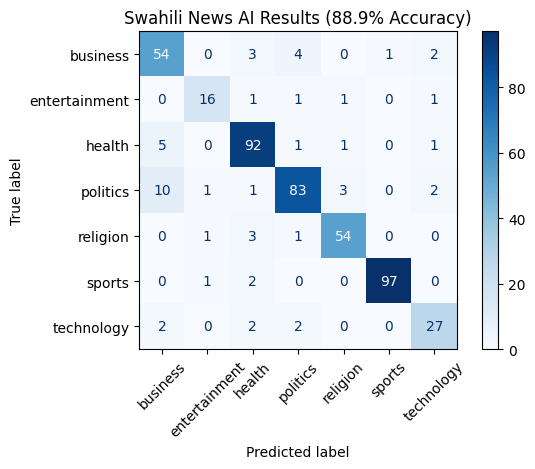

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<6 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<9 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        fn, *processed_input, limiter=self.limiter
        ^^^^^^^^^^^^^^

Done! Ready to download.


In [ ]:
import shutil
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Get the model's predictions on the test data
test_output = trainer.predict(tokenized_data["test"])
predicted_labels = test_output.predictions.argmax(axis=1)
true_labels = test_output.label_ids

# 2. Draw and save the Confusion Matrix chart for our presentation
ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predicted_labels,
    display_labels=label_names,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Swahili News AI Results (88.9% Accuracy)")
plt.tight_layout()
plt.savefig("results_chart.png")
plt.show()

# 3. Zip the saved model folder so we can download it
shutil.make_archive("my_swahili_model", "zip", "./final_swahili_ai")
print("Done! Ready to download.")
